# How Does Sticking Probability Affect the Structure of a DLA Cluster?

Diffusion-limited aggregation (DLA) simulations on a square and a hexagonal lattice, comparing sticking probabilities of 1.0, 0.5, and 0.1.

**How to run:** choose **Runtime → Run all**. The cells depend on the ones above them, so run them in order. The fractal dimension section takes about a minute.

## 1. Setup and the DLA simulation (square lattice)

In [1]:
import random
import math
import matplotlib.pyplot as plt

`run_dla(n_particles, stick_prob)` grows a cluster:

1. Start with one seed particle at (0, 0).
2. Launch each new walker from a random point on a circle 5 steps outside the cluster's current edge.
3. Walk randomly (up, down, left, right) for up to 5,000 steps.
4. If the walker is next to the cluster and its site is empty, it sticks with probability `stick_prob`; otherwise it keeps walking.
5. A walker that never sticks is discarded.

The function returns a dictionary `{(x, y): arrival order}`.

In [2]:
def run_dla(n_particles, stick_prob):
  cluster = {(0,0): 0}
  moves = [(1,0),(-1,0),(0,1),(0,-1)]
  max_r = 1

  for p in range(n_particles):
    R = max_r + 5
    angle = random.uniform(0, 2*math.pi)
    x = round(R*math.cos(angle))
    y = round(R*math.sin(angle))

    for i in range(5000):
      dx, dy = random.choice(moves)
      x = x + dx
      y = y + dy
      touching = ((x, y-1) in cluster) or ((x+1, y) in cluster) or ((x-1, y) in cluster) or ((x, y+1) in cluster)

      if touching and (x, y) not in cluster and random.random() < stick_prob:
        cluster[(x, y)] = p
        max_r = max(max_r, math.hypot(x, y))
        break

  return cluster

## 2. Experiment 1: effect of sticking probability

Three clusters of 400 walkers, colored by arrival order (dark = early, bright = late). Each panel is one random run (seed 42).

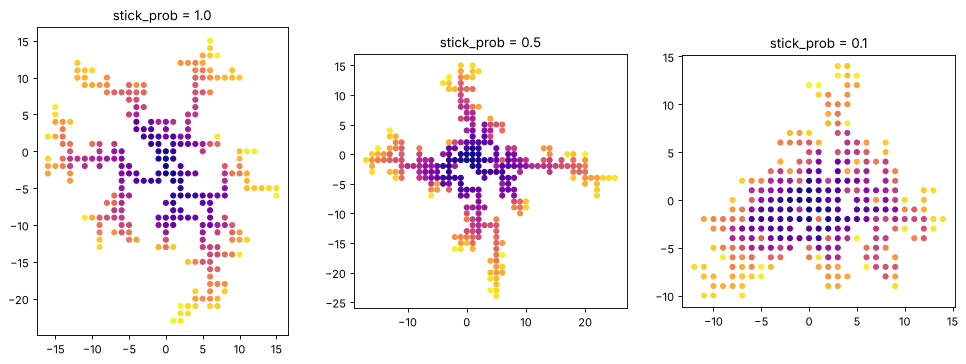

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, sp in zip(axes, [1.0, 0.5, 0.1]):
  random.seed(42)
  cluster = run_dla(400, sp)

  xs = []
  ys = []
  colors = []

  for point in cluster:
      xs.append(point[0])
      ys.append(point[1])
      colors.append(cluster[point])

  ax.scatter(xs, ys, c=colors, cmap="plasma", s=20)
  ax.set_title(f"stick_prob = {sp}")
  ax.set_aspect("equal")

plt.savefig("dla_stickiness.png", dpi=150, bbox_inches="tight")
plt.show()

### The same cluster drawn as branches

Instead of dots, draw a line wherever two particles are neighbors.

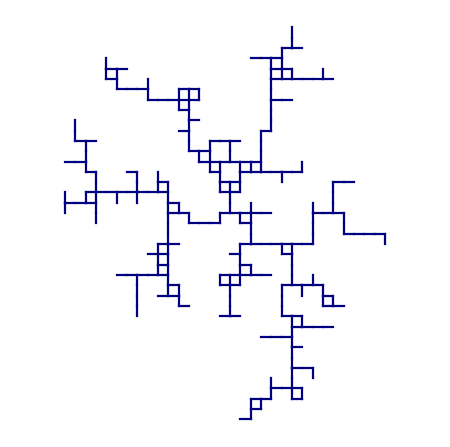

In [4]:
random.seed(42)
cluster = run_dla(400, 1.0)

plt.figure(figsize=(7, 7))
for (x, y) in cluster:
    if (x + 1, y) in cluster:                 # is there a neighbor to the right?
        plt.plot([x, x + 1], [y, y], color="navy", linewidth=2)
    if (x, y + 1) in cluster:                 # is there a neighbor above?
        plt.plot([x, x], [y, y + 1], color="navy", linewidth=2)

plt.axis("equal")
plt.axis("off")
plt.show()

## 3. Measuring the fractal dimension

If the number of particles within radius *r* grows like *r*^D, then D is the fractal dimension: a solid disc has D = 2, and a thin branching cluster has D below 2. I estimate it from two radii:

D = log(N_big / N_small) / log(r_big / r_small)

In [5]:
def count_within(cluster, r):
    count = 0
    for point in cluster:
        if math.hypot(point[0], point[1]) <= r:
            count = count + 1
    return count

def fractal_dimension(cluster, r_small, r_big):
    n_small = count_within(cluster, r_small)
    n_big = count_within(cluster, r_big)
    return math.log(n_big / n_small) / math.log(r_big / r_small)

### First attempt: radius 5 and 15 (flawed)

The compact 0.1 clusters are only about 12 steps across, so a circle of radius 15 is bigger than the whole cluster. The count stops growing and D looks artificially low (0.1 gives D = 1.17). **This result is a measurement artifact, not a real finding.**

In [6]:
for sp in [1.0, 0.5, 0.1]:
    results = []
    for run in range(5):
        random.seed(run)
        cluster = run_dla(400, sp)
        results.append(fractal_dimension(cluster, 5, 15))
    average = sum(results) / len(results)
    print(sp, "average D =", round(average, 2))

1.0 average D = 1.44
0.5 average D = 1.43
0.1 average D = 1.17


### Fair measurement: radius 4 and 10

With circles that fit inside every cluster, the result changes. Five runs per sticking probability (seeds 0 to 4); the five individual values are printed so you can see the run-to-run spread.

In [7]:
for sp in [1.0, 0.5, 0.1]:
    results = []
    for run in range(5):
        random.seed(run)
        cluster = run_dla(400, sp)
        results.append(fractal_dimension(cluster, 4, 10))
    average = sum(results) / len(results)
    print(sp, "average D =", round(average, 2), [round(r, 2) for r in results])

1.0 average D = 1.48 [1.6, 1.32, 1.31, 1.69, 1.46]
0.5 average D = 1.63 [1.42, 1.63, 1.67, 1.93, 1.49]
0.1 average D = 1.62 [1.67, 1.67, 1.58, 1.58, 1.62]


## 4. Experiment 2: hexagonal lattice and snowflake-style images

On a hexagonal lattice, each particle has 6 neighbors, so branches grow at 60° angles. Positions are stored as grid coordinates `(q, r)`, and `to_xy` converts them to real positions for drawing.

In [8]:
S3 = math.sqrt(3) / 2

def to_xy(q, r):                      # grid position -> real x, y for drawing
    return q + r / 2, r * S3

def run_hex_dla(n_particles, stick_prob):
    cluster = {(0, 0): 0}
    moves = [(1,0), (-1,0), (0,1), (0,-1), (1,-1), (-1,1)]
    max_r = 1
    for p in range(1, n_particles + 1):
        R = max_r + 5
        angle = random.uniform(0, 2 * math.pi)
        x0 = R * math.cos(angle)
        y0 = R * math.sin(angle)
        r = round(y0 / S3)
        q = round(x0 - r / 2)
        for i in range(5000):
            dq, dr = random.choice(moves)
            q = q + dq
            r = r + dr
            touching = any((q + a, r + b) in cluster for a, b in moves)
            if touching and (q, r) not in cluster and random.random() < stick_prob:
                cluster[(q, r)] = p
                x, y = to_xy(q, r)
                max_r = max(max_r, math.hypot(x, y))
                break
    return cluster

### Six-fold rotation (a drawing trick)

Rotating a small cluster by 60° six times gives a snowflake-style image. **This is a drawing trick, not a physical simulation of snowflake growth.**

In [9]:
def six_fold(cluster):
    result = {}
    for (q, r), t in cluster.items():
        a, b = q, r
        for k in range(6):
            result[(a, b)] = t
            a, b = -b, a + b          # rotate by 60 degrees
    return result

### Snowflake-style images at each sticking probability (same scale)

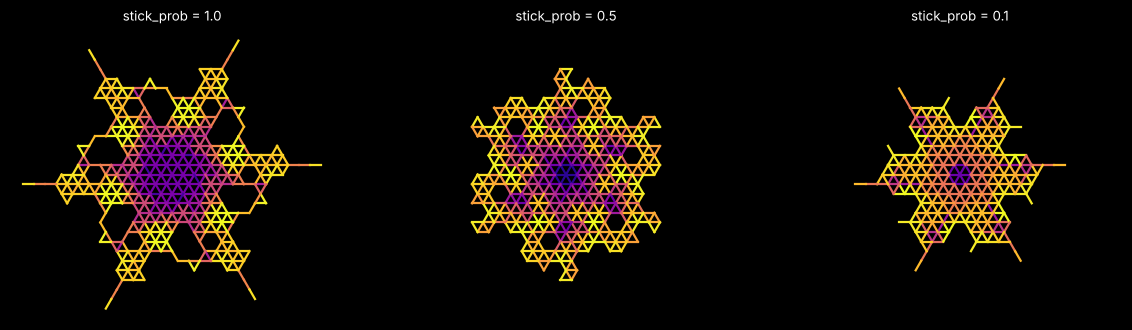

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6), facecolor="black", sharex=True, sharey=True)
cmap = plt.get_cmap("plasma")

for ax, sp in zip(axes, [1.0, 0.5, 0.1]):
    random.seed(2)
    cluster = run_hex_dla(120, sp)
    snow = six_fold(cluster)
    biggest = max(snow.values())

    for (q, r), t in snow.items():
        x, y = to_xy(q, r)
        for a, b in [(1,0), (0,1), (1,-1)]:
            if (q + a, r + b) in snow:
                x2, y2 = to_xy(q + a, r + b)
                t2 = snow[(q + a, r + b)]
                ax.plot([x, x2], [y, y2], color=cmap(max(t, t2) / biggest), linewidth=2)

    ax.set_title(f"stick_prob = {sp}", color="white")
    ax.set_aspect("equal")
    ax.axis("off")

plt.savefig("snowflakes_stickiness.png", dpi=200, bbox_inches="tight", facecolor="black")
plt.show()

### One snowflake, colored by arrival order

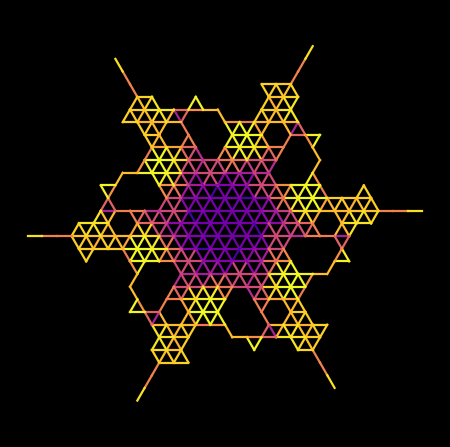

In [11]:
random.seed(2)
cluster = run_hex_dla(120, 1.0)
snow = six_fold(cluster)
biggest = max(snow.values())
cmap = plt.get_cmap("plasma")

plt.figure(figsize=(7, 7), facecolor="black")
for (q, r), t in snow.items():
    x, y = to_xy(q, r)
    for a, b in [(1,0), (0,1), (1,-1)]:
        if (q + a, r + b) in snow:
            x2, y2 = to_xy(q + a, r + b)
            t2 = snow[(q + a, r + b)]
            plt.plot([x, x2], [y, y2], color=cmap(max(t, t2) / biggest), linewidth=2)
plt.axis("equal")
plt.axis("off")
plt.savefig("snowflake_color.png", dpi=200, bbox_inches="tight", facecolor="black")
plt.show()